In [1]:
# === Ô GHI LOG ===
import logging, sys, datetime, warnings
from pathlib import Path
TEN_NOTEBOOK = "01_E0.5_nghe_si_va_the_loai_Han"
NGUOI_CHAY   = "Han"

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").exists())  # thư mục gốc repo
thu_muc_log = ROOT / "logs" / "eda_log"   # log các notebook EDA để riêng
thu_muc_log.mkdir(parents=True, exist_ok=True)
file_log = thu_muc_log / f"{datetime.datetime.now():%Y-%m-%d_%H%M}_{TEN_NOTEBOOK}.log"
tep_log = open(file_log, "a", encoding="utf-8", buffering=1)

if hasattr(sys.stdout, "echo"):                  # chạy trong Jupyter / VS Code: nhờ kernel chép thêm ra file, không thay sys.stdout
    sys.stdout.echo = tep_log
    sys.stderr.echo = tep_log
else:                                            # chạy bằng python thường
    class GhiCaHai:
        def __init__(self, man_hinh, tep): self.man_hinh, self.tep = man_hinh, tep
        def write(self, s): self.man_hinh.write(s); self.tep.write(s); return len(s)
        def flush(self): self.man_hinh.flush(); self.tep.flush()
        def __getattr__(self, ten): return getattr(self.man_hinh, ten)
    sys.stdout = GhiCaHai(sys.__stdout__, tep_log)

logging.basicConfig(stream=sys.stdout, level=logging.INFO, force=True,
                    format="%(asctime)s | %(levelname)s | %(message)s", datefmt="%Y-%m-%d %H:%M:%S")
logging.captureWarnings(True)
log = logging.getLogger(TEN_NOTEBOOK)
log.info(f"Bắt đầu chạy {TEN_NOTEBOOK} – người chạy: {NGUOI_CHAY} – file log: {file_log}")

2026-11-14 18:13:20 | INFO | Bắt đầu chạy 01_E0.5_nghe_si_va_the_loai_Han – người chạy: Han – file log: /Users/caongochan/Documents/Challenge_2_Music_Genre_Classification/logs/2026-11-14_1813_01_E0.5_nghe_si_va_the_loai_Han.log


# E0.5 – Nghệ sĩ nói lên bao nhiêu về thể loại? (C2 – Music Genre)

| | |
|---|---|
| **Tác giả** | Cao Ngọc Hân – Nhóm 11 |
| **Ngày tạo** | 14/11/2026 |
| **Thí nghiệm** | E0.5 – Nghệ sĩ nói lên bao nhiêu về thể loại? |
| **Câu hỏi nghiên cứu** | RQ0: Đặc trưng âm thanh nào phân biệt các thể loại tốt nhất? · RQ1: cách xử lý cột nghệ sĩ |
| **Đọc vào** | `data/raw/train.csv`, `test.csv` |
| **Ghi ra** | `figures/eda/c2_E0.5_nghe_si.csv`, `c2_E0.5_nghe_si.png`, `c2_E0.5_tom_tat.txt` |

**Lịch sử sửa**

| Ngày | Người | Nội dung |
|---|---|---|
| 08/11/2026 | Hân | Viết trong `01_eda_Han.ipynb` (E0.1–E0.6 chung một notebook) |
| 14/11/2026 | Hân | Tách thành notebook riêng; thêm ô ghi log ra `logs/` |

Notebook chỉ dùng thống kê và mô hình đơn giản (hồi quy logistic). Mô hình mạnh là việc của Nhung.

**Cách chạy:** chạy các notebook EDA theo thứ tự E0.1 → E0.6 (Run All). File log nằm ở `logs/eda_log/`. Bản gộp đọc từ trên xuống: `00_EDA_tong_hop_C2_Han.ipynb`.

In [2]:
import os, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.feature_selection import mutual_info_classif, f_classif
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)
sns.set_theme(style="whitegrid", font_scale=1.0)

SEED = 42
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").exists())  # notebook nằm ở notebooks/eda/
DATA = ROOT / "data" / "raw"
FIG = ROOT / "figures" / "eda"
FIG.mkdir(parents=True, exist_ok=True)

# W&B: USE_WANDB là công tắc chung; LOG chọn thí nghiệm nào được log ở lần chạy này.
# Các run W&B của E0.1–E0.6 đã log ngày 08/11 (từ 01_eda_Han.ipynb).
# Để USE_WANDB = False khi chạy lại để không tạo run trùng; bật True nếu cần log run mới.
USE_WANDB = False
LOG = {"E0.5": True}
WANDB_ENTITY = "sgu-mayhoc-nhom11"
WANDB_PROJECT = "challenge-2-music-genre-classification"
log.info(f"ROOT: {ROOT}")

2026-11-14 18:13:22 | INFO | ROOT: /Users/caongochan/Documents/Challenge_2_Music_Genre_Classification


In [3]:
train = pd.read_csv(DATA / "train.csv")
test = pd.read_csv(DATA / "test.csv")
TARGET, ID = "Class", "Id"
TEXT_COLS = ["Artist Name", "Track Name"]
print("train:", train.shape, "| test:", test.shape)
train.head()

train: (14396, 18) | test: (3600, 17)


,Id,Artist Name,Track Name,Popularity,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_in min/ms,time_signature,Class
0,1,Marina Maximilian,Not Afraid,37.0,0.334,0.536,9.0,-6.649,0,0.0381,0.378000,NaN,0.106,0.235,152.429,204947.0,4,9
1,2,The Black Keys,Howlin' for You,67.0,0.725,0.747,11.0,-5.545,1,0.0876,0.027200,0.0468,0.104,0.380,132.921,191956.0,4,6
2,3,Royal & the Serpent,phuck u,NaN,0.584,0.804,7.0,-6.094,1,0.0619,0.000968,0.6350,0.284,0.635,159.953,161037.0,4,10
3,4,Detroit Blues Band,Missing You,12.0,0.515,0.308,NaN,-14.711,1,0.0312,0.907000,0.0213,0.300,0.501,172.472,298093.0,3,2
4,5,Coast Contra,My Lady,48.0,0.565,0.777,6.0,-5.096,0,0.2490,0.183000,NaN,0.211,0.619,88.311,254145.0,4,5


In [4]:
# Chuẩn bị chung (lấy lại từ E0.1, E0.2): tách đặc trưng; đổi thời lượng về phút và điền thiếu bằng trung vị
# (chỉ để phân tích, không phải pipeline mô hình); 5 fold phân tầng và hồi quy logistic dùng chung
X = train.drop(columns=[ID, TARGET])
y = train[TARGET]
num_cols = [c for c in X.columns if c not in TEXT_COLS]
Xa = X[num_cols].copy()
Xa["duration_in min/ms"] = np.where(Xa["duration_in min/ms"] < 30, Xa["duration_in min/ms"],
                                    Xa["duration_in min/ms"] / 60000)
Xa = Xa.rename(columns={"duration_in min/ms": "duration_min"})
num_cols = list(Xa.columns)
Xa = Xa.fillna(Xa.median())

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
def logit():
    return make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, class_weight="balanced"))
baseline_f1 = 1 / y.nunique()
log.info(f"{len(num_cols)} đặc trưng số, {y.nunique()} thể loại, macro-F1 ngẫu nhiên ≈ {baseline_f1:.3f}")

2026-11-14 18:13:22 | INFO | 14 đặc trưng số, 11 thể loại, macro-F1 ngẫu nhiên ≈ 0.091


## E0.5 – Nghệ sĩ nói lên bao nhiêu về thể loại?

Ở E0.1 thấy phần lớn bài của cùng một nghệ sĩ có cùng thể loại. Thí nghiệm này đo xem thông tin đó mạnh tới mức nào, so ba cách dự đoán (stratified 5-fold, cùng các fold như E0.4):

1. **Chỉ âm thanh:** hồi quy logistic trên 14 đặc trưng số.
2. **Chỉ nghệ sĩ:** đoán thể loại phổ biến nhất của nghệ sĩ trong tập huấn luyện; nghệ sĩ chưa gặp thì đoán lớp đông nhất.
3. **Âm thanh + nghệ sĩ:** nghệ sĩ đã gặp thì đoán theo nghệ sĩ, chưa gặp thì dùng mô hình âm thanh.

Trong mỗi fold, 59% bài có nghệ sĩ đã gặp ở phần huấn luyện (ở tập test thật: 64%); với các bài này, đoán theo nghệ sĩ đúng 63%.


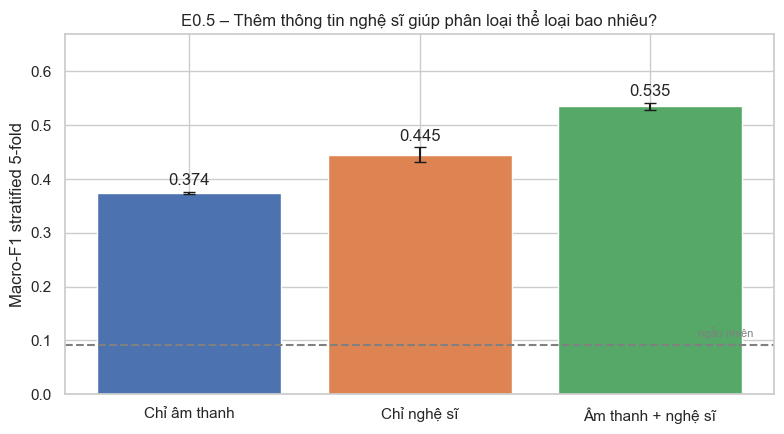

,macro_F1,macro_F1_std,accuracy,accuracy_std
cach,,,,
Chỉ âm thanh,0.374,0.002,0.371,0.004
Chỉ nghệ sĩ,0.445,0.014,0.451,0.010
Âm thanh + nghệ sĩ,0.535,0.007,0.542,0.005


In [5]:
from sklearn.metrics import f1_score, accuracy_score
artist = train["Artist Name"]
global_major = y.mode().iloc[0]
rows, seen_rates, seen_acc = [], [], []
for fold, (tr_idx, va_idx) in enumerate(skf.split(Xa, y)):
    model = logit().fit(Xa.iloc[tr_idx], y.iloc[tr_idx])
    p_audio = pd.Series(model.predict(Xa.iloc[va_idx]), index=va_idx)
    art_major = (pd.DataFrame({"a": artist.iloc[tr_idx], "c": y.iloc[tr_idx]})
                   .groupby("a")["c"].agg(lambda s: s.value_counts().idxmax()))
    a_va = artist.iloc[va_idx]
    seen = a_va.isin(art_major.index).to_numpy()
    p_artist = pd.Series(np.where(seen, a_va.map(art_major), global_major), index=va_idx)
    p_combo = pd.Series(np.where(seen, a_va.map(art_major), p_audio), index=va_idx)
    yt = y.iloc[va_idx]
    for name, p in [("Chỉ âm thanh", p_audio), ("Chỉ nghệ sĩ", p_artist), ("Âm thanh + nghệ sĩ", p_combo)]:
        rows.append({"cach": name, "fold": fold, "macro_F1": f1_score(yt, p.astype(int), average="macro"),
                     "accuracy": accuracy_score(yt, p.astype(int))})
    seen_rates.append(seen.mean())
    seen_acc.append(accuracy_score(yt[seen], p_artist[seen].astype(int)))

e05 = pd.DataFrame(rows)
e05_tbl = e05.groupby("cach", sort=False)[["macro_F1", "accuracy"]].agg(["mean", "std"]).round(3)
e05_tbl.columns = ["macro_F1", "macro_F1_std", "accuracy", "accuracy_std"]
e05_tbl.to_csv(FIG / "c2_E0.5_nghe_si.csv")
seen_rate, seen_artist_acc = float(np.mean(seen_rates)), float(np.mean(seen_acc))
test_seen = float(test["Artist Name"].isin(train["Artist Name"]).mean())
print(f"Trong mỗi fold, {seen_rate:.0%} bài có nghệ sĩ đã gặp ở phần huấn luyện "
      f"(ở tập test thật: {test_seen:.0%}); với các bài này, đoán theo nghệ sĩ đúng {seen_artist_acc:.0%}.")

fig, ax = plt.subplots(figsize=(8, 4.5))
order = ["Chỉ âm thanh", "Chỉ nghệ sĩ", "Âm thanh + nghệ sĩ"]
vals, errs = e05_tbl.loc[order, "macro_F1"], e05_tbl.loc[order, "macro_F1_std"]
bars = ax.bar(order, vals, yerr=errs, capsize=4, color=["#4C72B0", "#DD8452", "#55A868"])
for b, v, e in zip(bars, vals, errs):
    ax.text(b.get_x() + b.get_width() / 2, v + e + 0.012, f"{v:.3f}", ha="center")
ax.axhline(baseline_f1, ls="--", color="gray"); ax.text(2.45, baseline_f1 + 0.015, "ngẫu nhiên", fontsize=8, color="gray", ha="right")
ax.set_ylabel("Macro-F1 stratified 5-fold"); ax.set_ylim(0, max(vals) * 1.25)
ax.set_title("E0.5 – Thêm thông tin nghệ sĩ giúp phân loại thể loại bao nhiêu?")
plt.tight_layout(); plt.savefig(FIG / "c2_E0.5_nghe_si.png", dpi=150); plt.show()
e05_tbl

## Tóm tắt E0.5

In [6]:
summary = f"""E0.5 (C2): macro-F1 chỉ âm thanh {e05_tbl.at['Chỉ âm thanh', 'macro_F1']:.3f}, chỉ nghệ sĩ {e05_tbl.at['Chỉ nghệ sĩ', 'macro_F1']:.3f}, âm thanh + nghệ sĩ {e05_tbl.at['Âm thanh + nghệ sĩ', 'macro_F1']:.3f}.
  {seen_rate:.0%} bài có nghệ sĩ đã gặp (test thật: {test_seen:.0%}); với các bài này đoán theo nghệ sĩ đúng {seen_artist_acc:.0%}."""
log.info("Tóm tắt E0.5:\n" + summary)
(FIG / "c2_E0.5_tom_tat.txt").write_text(summary, encoding="utf-8")

2026-11-14 18:13:23 | INFO | Tóm tắt E0.5:
E0.5 (C2): macro-F1 chỉ âm thanh 0.374, chỉ nghệ sĩ 0.445, âm thanh + nghệ sĩ 0.535.
  59% bài có nghệ sĩ đã gặp (test thật: 64%); với các bài này đoán theo nghệ sĩ đúng 63%.


174

## Log lên W&B (minh chứng)

In [7]:
if USE_WANDB:
    import wandb
    def log_run(exp, name, metrics, tables, images, config=None):
        if not LOG.get(exp):
            print(f"Bỏ qua {exp} (LOG = False)"); return
        run = wandb.init(entity=WANDB_ENTITY, project=WANDB_PROJECT, name=name,
                         tags=[exp, "Han", "EDA"], config={"seed": SEED, **(config or {})})
        run.log({**metrics,
                 **{k: wandb.Table(dataframe=v) for k, v in tables.items()},
                 **{f.removesuffix(".png"): wandb.Image(str(FIG / f)) for f in images}})
        run.finish()

    log_run("E0.5", "c2-E0.5-Han-nghe-si-va-the-loai",
            {"f1_audio": float(e05_tbl.at["Chỉ âm thanh", "macro_F1"]),
             "f1_artist": float(e05_tbl.at["Chỉ nghệ sĩ", "macro_F1"]),
             "f1_audio_artist": float(e05_tbl.at["Âm thanh + nghệ sĩ", "macro_F1"]),
             "seen_artist_rate": seen_rate, "seen_artist_accuracy": seen_artist_acc, "test_seen_artist_rate": test_seen},
            {"bang_so_sanh": e05_tbl.reset_index(names="cach")}, ["c2_E0.5_nghe_si.png"],
            {"cv": "stratified 5-fold", "audio_model": "LogisticRegression(class_weight=balanced)"})

## Nhật ký

- 08/11/2026 – Viết E0.5 lần đầu trong notebook `01_eda_Han.ipynb`. Commit `fa7d8ad`.
- 14/11/2026 – Tách E0.5 ra thành notebook riêng `01_E0.5_nghe_si_va_the_loai_Han.ipynb`, thêm ô ghi log. Commit `eaa2795`.